# EDA: датасет Lenta

Датасет `lenta` из scikit-uplift описывает SMS-рассылку сети «Лента». Строка — клиент: покупки до кампании, анкета и отклики на прошлые сообщения.

- Таргет `response_att` — визит в магазин после кампании.
- Тритмент `group`: `test` получил рассылку, `control` нет.
- Задача разбора — понять, подходят ли данные для uplift-модели: качество полей, средний эффект, рандомизация, состав признаков и сегменты, где эффект выше или ниже.

`fetch_lenta` отдаёт матрицу признаков отдельно от таргета и группы. Словарь ниже описывает поля исходной выгрузки, включая `group` и `response_att`.

## Содержание

1. Качество данных: размер, пропуски, аномалии, хвосты.
2. Тритмент, таргет и средний эффект (ATE) с доверительным интервалом.
3. Рандомизация: SMD по признакам и модель, которая пытается отличить test от control.
4. Признаки: связь с визитом внутри контроля, одномерная сила, избыточность по Спирмену.
5. Гетерогенность эффекта по бинам признаков.
6. Что брать в модель: признаки, сплит, метрики.


In [1]:
!pip install -q scikit-uplift statsmodels lightgbm scikit-learn


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st
from IPython.display import display

from sklift.datasets import fetch_lenta

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 25)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

BLUE, RED, GREY, GREEN = "#2f5fa8", "#c23b3b", "#8a8f99", "#2e7d5b"
LEAK = ["response_sms", "response_viber"]
RANDOM_STATE = 42


/Users/kirill/miniconda3/envs/hw/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Описание признаков

| Признак | Описание |
|---|---|
| `CardHolder` | ID клиента |
| `customer_age` | возраст клиента |
| `children` | количество детей |
| `cheque_count_[3,6,12]m_g*` | число чеков клиента за 3, 6 и 12 месяцев до кампании; `g*` означает товарную группу |
| `crazy_purchases_cheque_count_[1,3,6,12]m` | число чеков с товарами, купленными в рамках маркетинговой акции «crazy», за 1, 3, 6 и 12 месяцев до кампании |
| `crazy_purchases_goods_count_[6,12]m` | количество товаров, купленных в рамках акции «crazy», за 6 и 12 месяцев до кампании |
| `disc_sum_6m_g34` | сумма скидок за последние 6 месяцев по товарной группе 34 |
| `food_share_[15d,1m]` | доля продуктов питания в покупках клиента за 15 дней и 1 месяц |
| `gender` | пол клиента |
| `group` | флаг группы: treatment (воздействие) или control (контроль) |
| `k_var_cheque_[15d,3m]` | коэффициент вариации среднего чека за 15 дней и 3 месяца |
| `k_var_cheque_category_width_15d` | коэффициент вариации среднего числа категорий (2-й уровень иерархии) в одном чеке за 15 дней |
| `k_var_cheque_group_width_15d` | коэффициент вариации среднего числа групп (1-й уровень иерархии) в одном чеке за 15 дней |
| `k_var_count_per_cheque_[15d,1m,3m,6m]_g*` | коэффициент вариации числа уникальных товаров (SKU) за 15 дней, 1, 3 и 6 месяцев по группе `g*` |
| `k_var_days_between_visits_[15d,1m,3m]` | коэффициент вариации среднего интервала между визитами за 15 дней, 1 и 3 месяца |
| `k_var_disc_per_cheque_15d` | коэффициент вариации суммы скидки за 15 дней |
| `k_var_disc_share_[15d,1m,3m,6m,12m]_g*` | коэффициент вариации размера скидки за 15 дней, 1, 3, 6 и 12 месяцев по группе `g*` |
| `k_var_discount_depth_[15d,1m]` | коэффициент вариации размера скидки за 15 дней и 1 месяц |
| `k_var_sku_per_cheque_15d` | коэффициент вариации числа уникальных товаров (SKU) в чеке за 15 дней |
| `k_var_sku_price_[15d,1m,3m,6m,12m]_g*` | коэффициент вариации цены за 15 дней, 1, 3, 6 и 12 месяцев по группе `g*` (в исходной документации ошибочно указан только 12m) |
| `main_format` | тип магазина (1 = магазин у дома, 0 = супермаркет) |
| `mean_discount_depth_15d` | средняя глубина скидки за 15 дней |
| `months_from_register` | число месяцев с момента регистрации |
| `perdelta_days_between_visits_15_30d` | разница в процентах между интервалами визитов в первой и во второй половине месяца |
| `promo_share_15d` | доля промотоваров в корзине клиента |
| `response_att` | бинарный таргет: визит в магазин |
| `response_sms` | доля откликов на прошлые SMS (отклик означает визит в магазин) |
| `response_viber` | доля откликов на прошлые сообщения в Viber (отклик означает визит в магазин) |
| `sale_count_[3,6,12]m_g*` | количество купленных товаров из группы `g*` за 3, 6 и 12 месяцев |
| `sale_sum_[3,6,12]m_g*` | сумма продаж по группе `g*` за 3, 6 и 12 месяцев |
| `stdev_days_between_visits_15d` | стнд. отклонение числа дней между визитами за 15 дней |
| `stdev_discount_depth_[15d,1m]` | стнд. отклонение суммы скидки за 15 дней и 1 месяц |

В матрице признаков возраст называется `age`. `response_sms` и `response_viber` лежат рядом с покупками, но по смыслу это другие отклики той же механики. В модель они не входят; в проверке баланса их видно отдельно.


## 1. Качество данных

Смотрим размер, дубли, константы, пропуски, допустимые диапазоны и правый хвост. Пропуск в покупках чаще означает, что покупок в этой группе за окно не было, поэтому долю NaN сравниваем между test и control, а не заполняем её сразу.


In [3]:
dataset = fetch_lenta()
X_raw, y, treatment = dataset.data, dataset.target, dataset.treatment

assert y.index.equals(X_raw.index)
assert treatment.index.equals(X_raw.index)

num_cols = X_raw.select_dtypes(include="number").columns.tolist()
# float32 облегчает матрицу ~687 тыс. × 193. Для долей и SMD точности хватает.
# Спирмен в разделе 4 считаем по X_raw, чтобы ранги совпали с полным разбором пар.
X = X_raw.copy()
X[num_cols] = X[num_cols].astype("float32")

t = treatment.eq("test")
n = len(X)
miss_all = X.isna().mean()
miss = X[num_cols].isna().mean()
nan_per_row = X[num_cols].isna().sum(axis=1)

desc = X[num_cols].agg(["mean", "std", "min", "median", "max"]).T
desc["p99"] = X[num_cols].quantile(0.99)
desc["miss"] = miss
desc["nunique"] = X[num_cols].nunique()
desc["tail_p99_to_max"] = desc["max"] / desc["p99"].replace(0, np.nan)

quality = pd.Series(
    {
        "строк": n,
        "признаков всего": X.shape[1],
        "числовых признаков": len(num_cols),
        "дублей по вектору признаков": int(X.duplicated().sum()),
        "признаков с пропусками": int((miss_all > 0).sum()),
        "признаков без пропусков": int((miss_all == 0).sum()),
        "числовых признаков с >90% NaN": int((miss > 0.9).sum()),
        "доля строк без пропусков": round(float((nan_per_row == 0).mean()), 4),
        "константных числовых признаков": int((desc["nunique"] <= 1).sum()),
        "числовых признаков с отрицательными значениями": int((desc["min"] < 0).sum()),
    },
    name="значение",
)

print(f"таргет: {y.name}")
print(f"тритмент: {treatment.name}")
print(treatment.value_counts())
print("доля таргета:")
print(y.value_counts(normalize=True).round(4))
display(quality.to_frame())
display(
    X[["age", "gender", "main_format", "months_from_register", "cheque_count_12m_g41"]].head(3)
)


таргет: response_att
тритмент: group
group
test       515892
control    171137
Name: count, dtype: int64
доля таргета:
response_att
0    0.8918
1    0.1082
Name: proportion, dtype: float64


,значение
строк,687029.0000
признаков всего,193.0000
числовых признаков,192.0000
дублей по вектору признаков,30.0000
признаков с пропусками,153.0000
признаков без пропусков,40.0000
числовых признаков с >90% NaN,0.0000
доля строк без пропусков,0.0082
константных числовых признаков,0.0000
числовых признаков с отрицательными значениями,0.0000


,age,gender,main_format,months_from_register,cheque_count_12m_g41
0,47.0,Ж,0.0,18.0,6.0
1,57.0,Ж,1.0,4.0,1.0
2,38.0,М,0.0,34.0,14.0


Признаков с пропусками: 153 из 193
Максимальная разница доли NaN между test и control: 0.0073


,na_share,na_test,na_control,diff_test_control
k_var_sku_price_15d_g49,0.7223,0.7209,0.7265,-0.0056
k_var_disc_share_15d_g49,0.7222,0.7208,0.7263,-0.0055
k_var_sku_price_15d_g34,0.6820,0.6811,0.6846,-0.0034
k_var_count_per_cheque_15d_g34,0.6820,0.6811,0.6846,-0.0034
k_var_disc_share_15d_g34,0.6819,0.6810,0.6844,-0.0034
k_var_count_per_cheque_15d_g24,0.6435,0.6422,0.6475,-0.0053
k_var_disc_share_15d_g24,0.6434,0.6421,0.6474,-0.0053
k_var_count_per_cheque_1m_g49,0.6033,0.6017,0.6082,-0.0065
k_var_sku_price_1m_g49,0.6033,0.6017,0.6082,-0.0065
k_var_disc_share_1m_g49,0.6031,0.6015,0.6080,-0.0065


Блоки с одинаковой долей NaN (доля NaN → сколько признаков), размер блока ≥ 3:


,признаков
0.00000,41
0.00453,32
0.13691,16
0.01249,4
0.19896,4


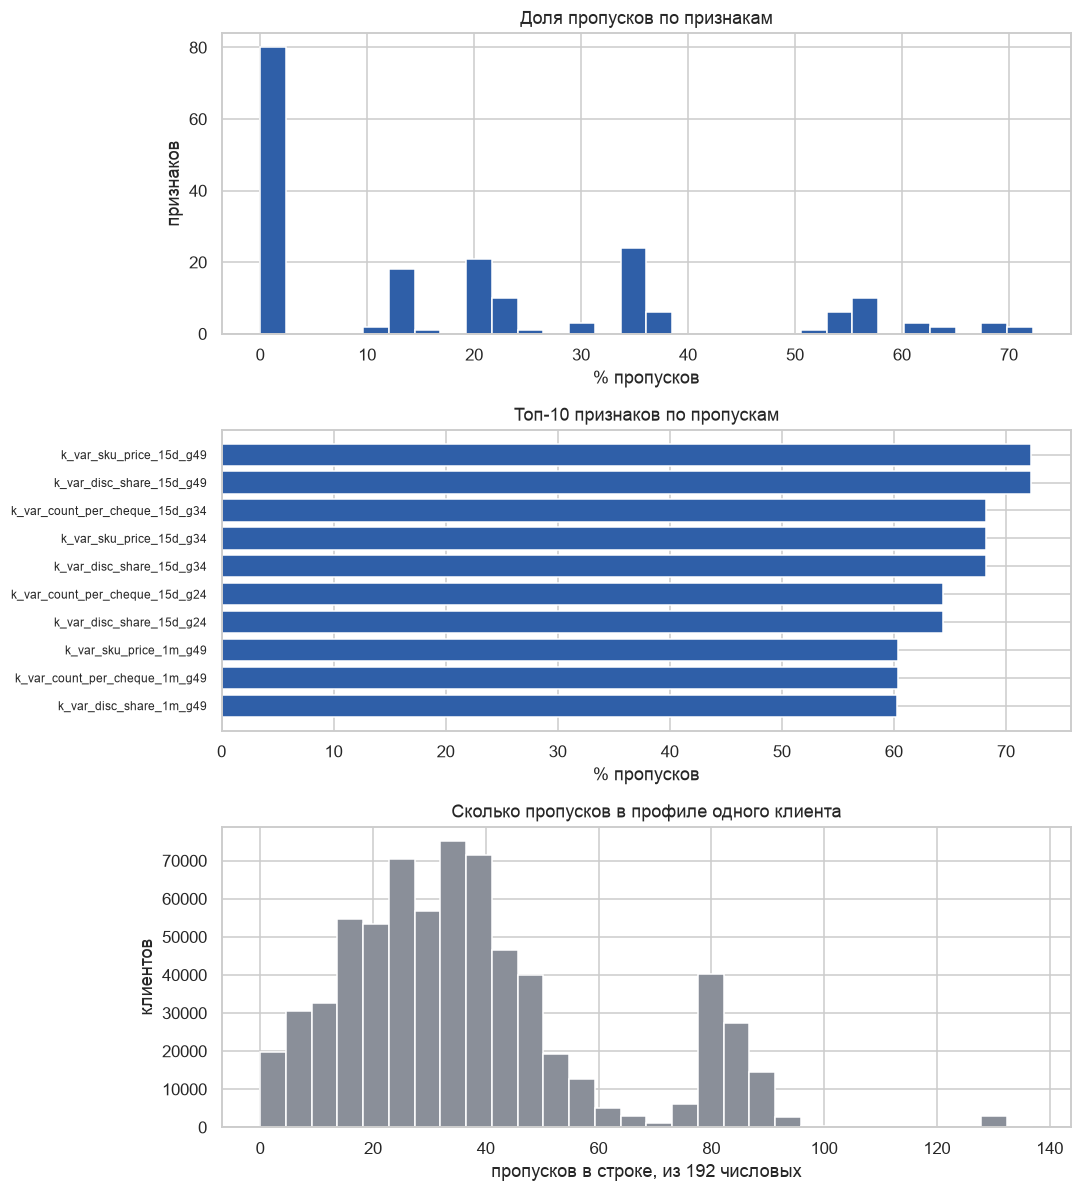

In [4]:
na = pd.DataFrame(
    {
        "na_share": miss_all,
        "na_test": X.loc[t].isna().mean(),
        "na_control": X.loc[~t].isna().mean(),
    }
)
na["diff_test_control"] = na["na_test"] - na["na_control"]
na_pos = na[na["na_share"] > 0].sort_values("na_share", ascending=False)

print(f"Признаков с пропусками: {len(na_pos)} из {X.shape[1]}")
print(
    "Максимальная разница доли NaN между test и control: "
    f"{na_pos['diff_test_control'].abs().max():.4f}"
)
display(na_pos.head(15).round(4))

blocks = miss.round(5).value_counts()
print("Блоки с одинаковой долей NaN (доля NaN → сколько признаков), размер блока ≥ 3:")
display(blocks[blocks >= 3].head(8).to_frame("признаков"))

fig, axes = plt.subplots(3, 1, figsize=(10, 11))

axes[0].hist(miss_all * 100, bins=30, color=BLUE)
axes[0].set_xlabel("% пропусков")
axes[0].set_ylabel("признаков")
axes[0].set_title("Доля пропусков по признакам")

top_miss = miss_all.sort_values(ascending=False).head(10).iloc[::-1]
axes[1].barh(top_miss.index, top_miss.values * 100, color=BLUE)
axes[1].set_xlabel("% пропусков")
axes[1].tick_params(axis="y", labelsize=8)
axes[1].set_title("Топ-10 признаков по пропускам")

axes[2].hist(nan_per_row, bins=30, color=GREY)
axes[2].set_xlabel(f"пропусков в строке, из {len(num_cols)} числовых")
axes[2].set_ylabel("клиентов")
axes[2].set_title("Сколько пропусков в профиле одного клиента")

fig.tight_layout()
plt.show()


In [5]:
age = X["age"]
print(age.describe(percentiles=[0.001, 0.01, 0.99, 0.999]).round(1))
print(f"Возраст < 14: {int((age < 14).sum())}")
print(f"Возраст = 0:  {int((age == 0).sum())}")
print(f"Возраст > 90: {int((age > 90).sum())}")
print(f"Доля возраста < 14: {(age < 14).mean():.4%}")

share_cols = [
    "food_share_15d",
    "food_share_1m",
    "promo_share_15d",
    "response_sms",
    "response_viber",
    "mean_discount_depth_15d",
]
print("Диапазоны долей:")
display(X[share_cols].agg(["min", "max"]).T)

print("Самый тяжёлый правый хвост (max / p99):")
display(
    desc.sort_values("tail_p99_to_max", ascending=False)[["median", "p99", "max", "miss"]]
    .head(5)
    .round(2)
)


count    675264.0
mean         43.7
std          14.8
min           0.0
0.1%         14.0
1%           18.0
99%          78.0
99.9%        85.0
max         100.0
Name: age, dtype: float64
Возраст < 14: 330
Возраст = 0:  1
Возраст > 90: 129
Доля возраста < 14: 0.0480%
Диапазоны долей:


,min,max
food_share_15d,0.0,1.0
food_share_1m,0.0,1.0
promo_share_15d,0.0,1.0
response_sms,0.0,1.0
response_viber,0.0,1.0
mean_discount_depth_15d,0.0,1.0


Самый тяжёлый правый хвост (max / p99):


,median,p99,max,miss
sale_sum_12m_g27,425.820007,11810.57,2.866854e+06,0.00
sale_count_6m_g44,3.000000,82.00,1.172100e+04,0.00
cheque_count_3m_g79,0.000000,5.00,4.830000e+02,0.14
cheque_count_6m_g79,0.000000,9.00,8.070000e+02,0.00
sale_count_6m_g24,5.240000,172.03,1.526136e+04,0.00


**Вывод.** В выборке 687 029 клиентов и 193 признака. Отрицательных значений нет, доли `food_share`, `promo_share`, `response_*` и `mean_discount_depth` лежат в [0, 1]. Число дублей строк и константных признаков печатает сводка выше.

Пропуски есть у 153 признаков из 193, у отдельных полей доля доходит примерно до 72%. Признаков без единого пропуска — 40. Полных строк около 0.8%. Одинаковая доля NaN у целых блоков признаков: пропуск появляется общим правилом, обычно это отсутствие покупок в товарной группе за окно. Максимальная разница доли NaN между test и control около 0.7 п.п. Таблица выше сравнивает именно группы. Как число пропусков у одного клиента связано с величиной эффекта, разобрано в разделе 5.

Возраст ниже 14 лет встречается у 330 клиентов, в том числе один нулевой, старше 90 — у 129. Вместе это около 0.07% выборки и похоже на ошибку анкеты. Перед обучением возраст < 14 заменяем на NaN. Счётные и денежные признаки сильно скошены: медиана, p99 и максимум расходятся в десятки раз. Деревья такой хвост переносят. Для линейной модели эти поля лучше логарифмировать.


## 2. Тритмент, таргет и средний эффект

ATE — насколько изменилась бы доля визитов, если бы рассылку получили все, по сравнению с тем, если бы её не получил никто. Это конверсия test минус конверсия control.

Отклик бинарный, группы независимые, поэтому равенство долей проверяем z-тестом пропорций.

- H0: конверсии в test и control равны.
- H1: конверсии различаются.

95% интервал для разности долей — Вальда, без поправки на непрерывность: границы стоят на ±1.96 стандартных ошибки разности.


In [6]:
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest

n_test = int(t.sum())
n_control = int((~t).sum())
k_test = int(y.loc[t].sum())
k_control = int(y.loc[~t].sum())

cr_test = k_test / n_test
cr_control = k_control / n_control
ate = cr_test - cr_control
stat, p_value = proportions_ztest([k_test, k_control], [n_test, n_control])
ci_low, ci_upp = confint_proportions_2indep(
    k_test,
    n_test,
    k_control,
    n_control,
    method="wald",
    compare="diff",
    correction=False,
    alpha=0.05,
)

print(f"test:    n={n_test:,}  конверсия={cr_test:.4f}  ({n_test / n:.1%})")
print(f"control: n={n_control:,}  конверсия={cr_control:.4f}  ({n_control / n:.1%})")
print(f"ATE: {ate * 100:.2f} п.п.")
print(f"Относительный прирост к контролю: {ate / cr_control:.1%}")
print(f"95% ДИ Вальда: [{ci_low * 100:.3f}; {ci_upp * 100:.3f}] п.п.")
print(f"Z-statistic: {stat:.2f}")
print(f"P-value: {p_value:.2e}")
print("Ноль лежит вне интервала." if ci_low > 0 or ci_upp < 0 else "Ноль лежит внутри интервала.")


test:    n=515,892  конверсия=0.1101  (75.1%)
control: n=171,137  конверсия=0.1026  (24.9%)
ATE: 0.75 п.п.
Относительный прирост к контролю: 7.4%
95% ДИ Вальда: [0.587; 0.922] п.п.
Z-statistic: 8.71
P-value: 3.09e-18
Ноль лежит вне интервала.


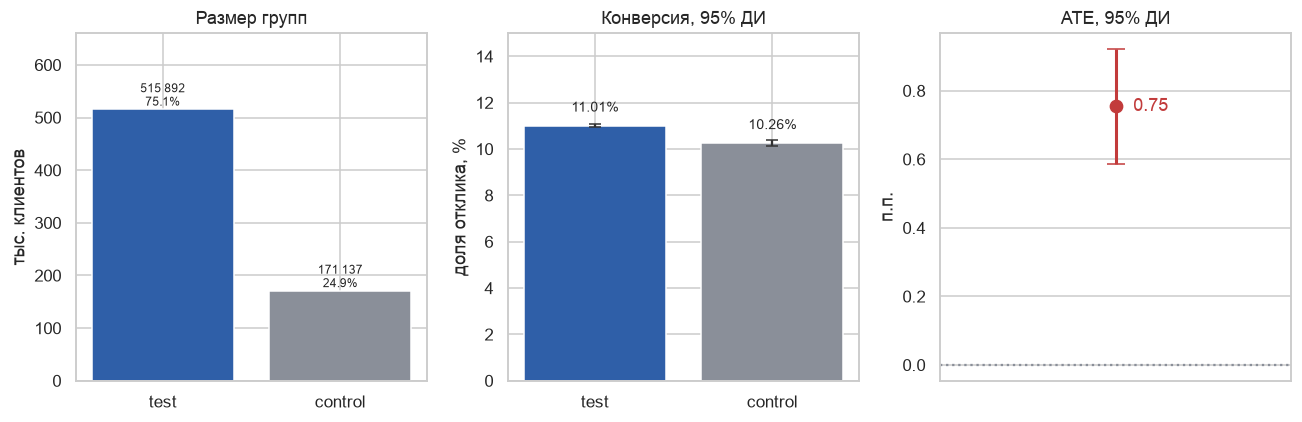

In [7]:
se_test = np.sqrt(cr_test * (1 - cr_test) / n_test)
se_control = np.sqrt(cr_control * (1 - cr_control) / n_control)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sizes = np.array([n_test, n_control]) / 1000
bars = axes[0].bar(["test", "control"], sizes, color=[BLUE, GREY])
axes[0].set_ylabel("тыс. клиентов")
axes[0].set_title("Размер групп")
axes[0].set_ylim(0, sizes.max() * 1.28)
for bar, count, share in zip(bars, (n_test, n_control), (n_test / n, n_control / n)):
    label = f"{count:,}".replace(",", " ") + "\n" + f"{share:.1%}"
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        label,
        ha="center",
        va="bottom",
        fontsize=8,
        color="#222",
    )

conv = np.array([cr_test, cr_control]) * 100
axes[1].bar(
    ["test", "control"],
    conv,
    color=[BLUE, GREY],
    yerr=1.96 * np.array([se_test, se_control]) * 100,
    capsize=4,
    ecolor="#333",
)
axes[1].set_ylim(0, 15)
axes[1].set_ylabel("доля отклика, %")
axes[1].set_title("Конверсия, 95% ДИ")
for x_pos, val in enumerate(conv):
    axes[1].text(x_pos, val + 0.6, f"{val:.2f}%", ha="center", fontsize=9)

ate_pp = ate * 100
axes[2].errorbar(
    [0],
    [ate_pp],
    yerr=[[ate_pp - ci_low * 100], [ci_upp * 100 - ate_pp]],
    fmt="o",
    color=RED,
    markersize=8,
    capsize=6,
    lw=2,
)
axes[2].axhline(0, color=GREY, ls=":")
axes[2].set_xlim(-0.8, 0.8)
axes[2].set_xticks([])
axes[2].set_ylabel("п.п.")
axes[2].set_title("ATE, 95% ДИ")
axes[2].text(0.08, ate_pp, f"{ate_pp:.2f}", color=RED, va="center")

fig.tight_layout()
plt.show()


**Вывод.** Сплит примерно 75/25 в пользу test. Конверсия 11.01% в test и 10.26% в control. ATE = +0.75 п.п., относительный прирост к контролю около 7.4%. 95% интервал примерно [+0.59; +0.92] п.п. и не содержит ноль, z-тест отвергает равенство конверсий. На фоне базовых 10% эффект небольшой, на этой выборке он устойчив.


## 3. Рандомизация

SMD = (среднее test − среднее control) / √((s² test + s² control) / 2)

Порог |SMD| <= 0.1. Средние считаются по наблюдаемым значениям, пропуск в среднее не входит.

`response_sms` и `response_viber` оставляем в таблице баланса: это сырой датасет, и по ним как раз видно, есть ли сдвиг. Из модели, которая проверяет рандомизацию, и из будущего обучения их убираем: это доли откликов на прошлые SMS и Viber, соседние исходы той же механики.

SMD смотрит поля по одному. Дальше LightGBM с фиксированными параметрами на подвыборке 150 тыс. и трёх стратифицированных фолдах пытается отличить test от control по всем признакам до кампании, включая пол. При удачной рандомизации ROC AUC близка к 0.5.

In [8]:
smd_src = X[num_cols].copy()
smd_src["gender_f"] = (X["gender"] == "Ж").astype("int8")
smd_src["gender_m"] = (X["gender"] == "М").astype("int8")
smd_src["gender_undefined"] = (
    (X["gender"] == "Не определен") | X["gender"].isna()
).astype("int8")

means = smd_src.groupby(treatment).mean()
vars_ = smd_src.groupby(treatment).var()
sd = np.sqrt((vars_.loc["test"] + vars_.loc["control"]) / 2)
smd = (means.loc["test"] - means.loc["control"]) / sd.where(sd > 0)
miss_diff = smd_src.loc[t].isna().mean() - smd_src.loc[~t].isna().mean()

smd_table = pd.DataFrame(
    {
        "mean_test": means.loc["test"],
        "mean_control": means.loc["control"],
        "smd": smd,
        "miss_diff": miss_diff,
    }
).sort_values("smd", key=lambda s: s.abs(), ascending=False)

clean = smd_table.drop(index=[c for c in LEAK if c in smd_table.index])
print(f"Признаков с |SMD| > 0.1: {int((smd_table['smd'].abs() > 0.1).sum())} из {len(smd_table)}")
print(f"max |SMD| без response_sms и response_viber: {clean['smd'].abs().max():.3f}")
print(
    "max |разница доли NaN| без этих двух полей: "
    f"{clean['miss_diff'].abs().max() * 100:.2f} п.п."
)
display(smd_table.head(15).round(4))


Признаков с |SMD| > 0.1: 1 из 195
max |SMD| без response_sms и response_viber: 0.026
max |разница доли NaN| без этих двух полей: 0.73 п.п.


,mean_test,mean_control,smd,miss_diff
response_sms,0.8006,0.7261,0.1981,0.0004
response_viber,0.2762,0.2509,0.0685,0.0004
gender_m,0.3519,0.3645,-0.0263,0.0000
gender_f,0.6340,0.6216,0.0255,0.0000
k_var_count_per_cheque_1m_g34,0.2185,0.2102,0.0254,-0.0038
crazy_purchases_cheque_count_12m,2.5204,2.4063,0.0249,0.0000
crazy_purchases_goods_count_12m,4.2438,4.0377,0.0244,0.0000
crazy_purchases_cheque_count_6m,1.0788,1.0293,0.0232,0.0000
k_var_disc_share_1m_g34,0.2625,0.2532,0.0224,-0.0037
crazy_purchases_cheque_count_3m,0.5851,0.5569,0.0216,0.0000


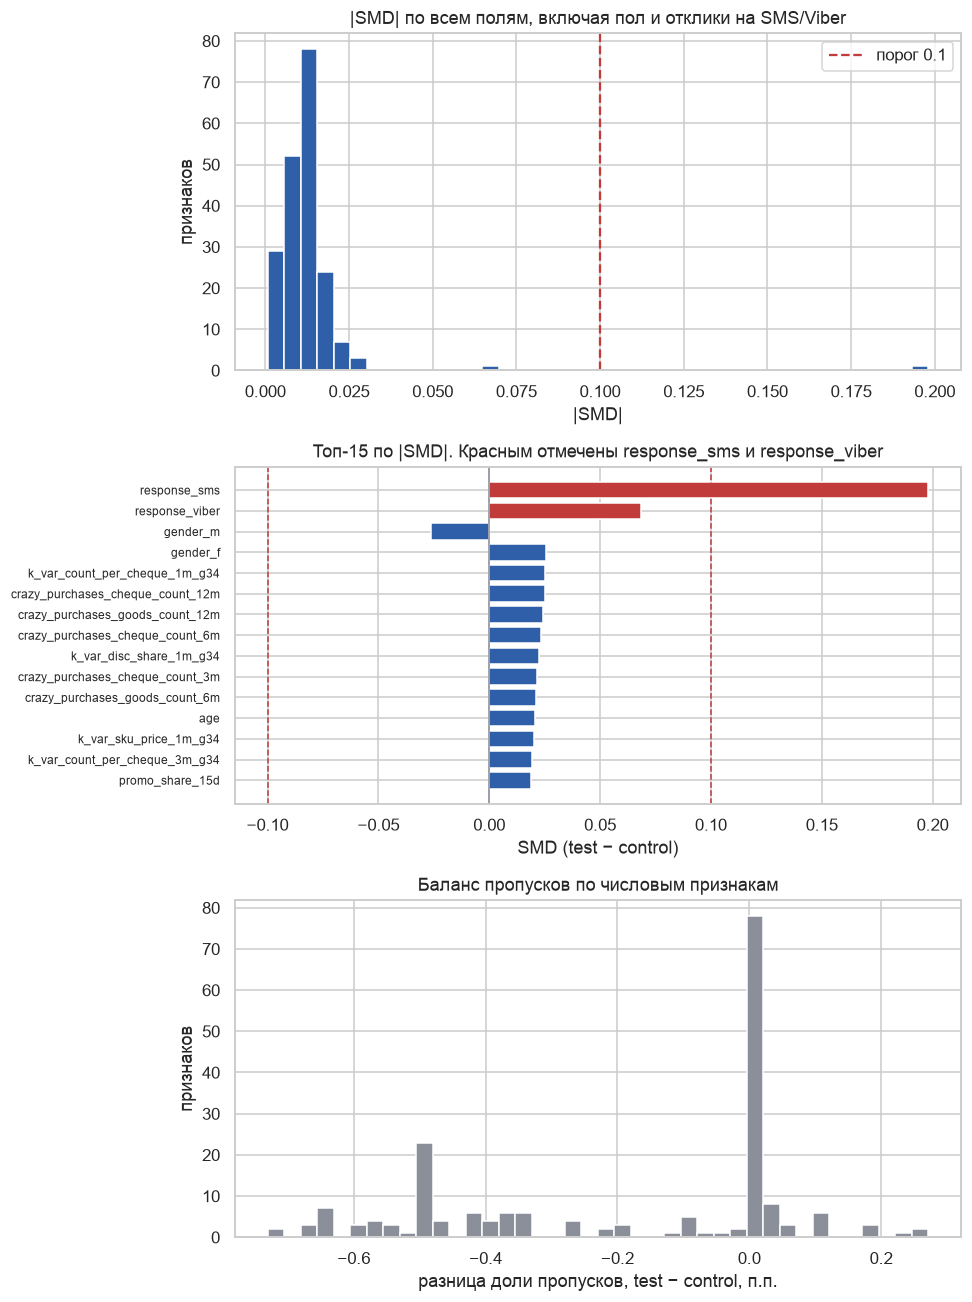

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(9, 12))

axes[0].hist(smd_table["smd"].abs(), bins=40, color=BLUE)
axes[0].axvline(0.1, color=RED, ls="--", label="порог 0.1")
axes[0].set_xlabel("|SMD|")
axes[0].set_ylabel("признаков")
axes[0].set_title("|SMD| по всем полям, включая пол и отклики на SMS/Viber")
axes[0].legend()

top = smd_table.head(15).iloc[::-1]
colors = [RED if name in LEAK else BLUE for name in top.index]
axes[1].barh(top.index, top["smd"], color=colors)
axes[1].axvline(0.1, color=RED, ls="--", lw=1)
axes[1].axvline(-0.1, color=RED, ls="--", lw=1)
axes[1].axvline(0, color=GREY, lw=1)
axes[1].set_xlabel("SMD (test − control)")
axes[1].tick_params(axis="y", labelsize=8)
axes[1].set_title("Топ-15 по |SMD|. Красным отмечены response_sms и response_viber")

num_miss = smd_table.loc[smd_table.index.intersection(num_cols), "miss_diff"] * 100
axes[2].hist(num_miss, bins=40, color=GREY)
axes[2].set_xlabel("разница доли пропусков, test − control, п.п.")
axes[2].set_ylabel("признаков")
axes[2].set_title("Баланс пропусков по числовым признакам")

fig.tight_layout()
plt.show()


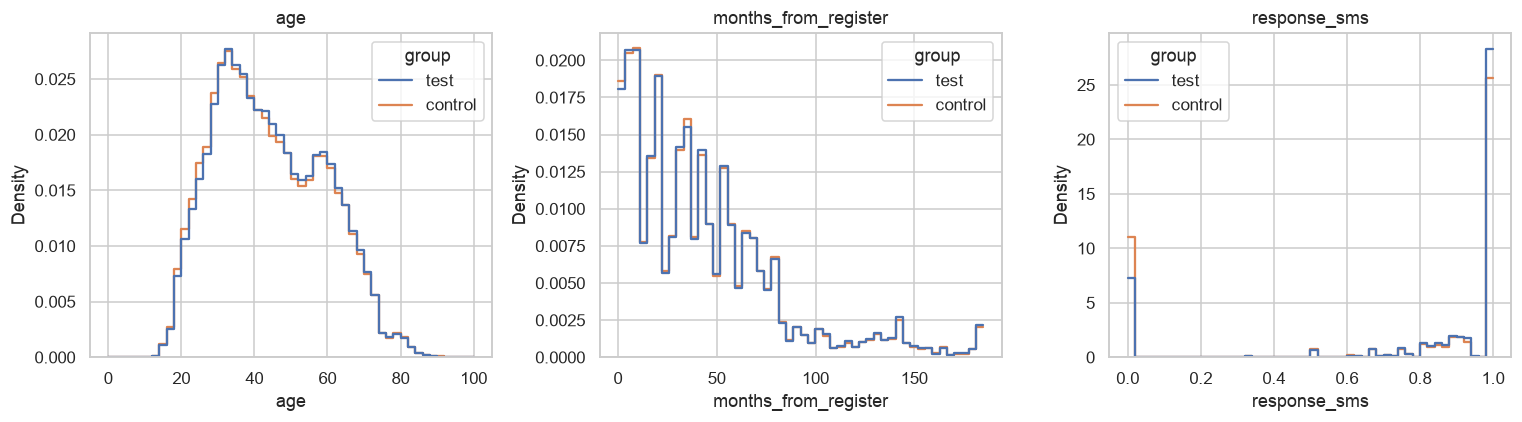

In [10]:
plot_df = X[["age", "months_from_register", "response_sms"]].copy()
plot_df["group"] = treatment.to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["age", "months_from_register", "response_sms"]):
    sns.histplot(
        data=plot_df,
        x=col,
        hue="group",
        hue_order=["test", "control"],
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        bins=50,
        ax=ax,
    )
    ax.set_title(col)

fig.tight_layout()
plt.show()


In [11]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold, cross_val_score

feat_cols = [c for c in num_cols if c not in LEAK]
X_model = X[feat_cols].copy()
X_model["gender_f"] = (X["gender"] == "Ж").astype("int8")
X_model["gender_m"] = (X["gender"] == "М").astype("int8")
X_model["gender_undefined"] = (
    (X["gender"] == "Не определен") | X["gender"].isna()
).astype("int8")

sub = np.random.default_rng(RANDOM_STATE).choice(n, size=150_000, replace=False)
ys = t.to_numpy()[sub].astype(np.int8)

model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    n_jobs=-1,
    verbose=-1,
    random_state=RANDOM_STATE,
)
cv = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
aucs = cross_val_score(model, X_model.iloc[sub], ys, cv=cv, scoring="roc_auc", n_jobs=1)
print("ROC AUC по фолдам:", np.round(aucs, 4))
print(f"средний ROC AUC = {aucs.mean():.4f}")


ROC AUC по фолдам: [0.5056 0.5075 0.5065]
средний ROC AUC = 0.5065


**Вывод.** |SMD| выше 0.1 только у `response_sms`, около 0.20: в test больше клиентов, которые раньше откликались на SMS. После исключения `response_sms` и `response_viber` максимальный |SMD| около 0.025, пол и остальные поля уложены в порог. Возраст и срок с регистрации в группах распределены одинаково, сдвиг виден на гистограмме `response_sms`.

Разница доли пропусков между группами остаётся в пределах долей процентного пункта.

Качество бустинга, разделяющего тритмент: средний ROC AUC около 0.5.


## 4. Признаки: связь с таргетом и избыточность

Связь с визитом считаем внутри контроля. В test отклик уже смешан с эффектом рассылки, и корреляция описывала бы не только склонность прийти в магазин. С бинарным таргетом это корреляция Пирсона. Рядом — доля визитов по квантильным бинам нескольких полей.

Дальше сплошной скрининг числовых признаков: доля самого частого значения, где пропуск считается отдельным значением, и univariate AUC / Gini по таргету на контроле. Gini = 2·AUC − 1.

Избыточность считаем по Спирмену на 100 тыс. строк.

,corr_y_ctrl
k_var_days_between_visits_15d,0.3007
k_var_disc_per_cheque_15d,0.2943
k_var_days_between_visits_1m,0.2811
k_var_cheque_15d,0.2779
stdev_discount_depth_15d,0.2631
k_var_sku_per_cheque_15d,0.2577
k_var_cheque_category_width_15d,0.2561
k_var_cheque_group_width_15d,0.2533
k_var_discount_depth_15d,0.2528
cheque_count_12m_g41,0.2318


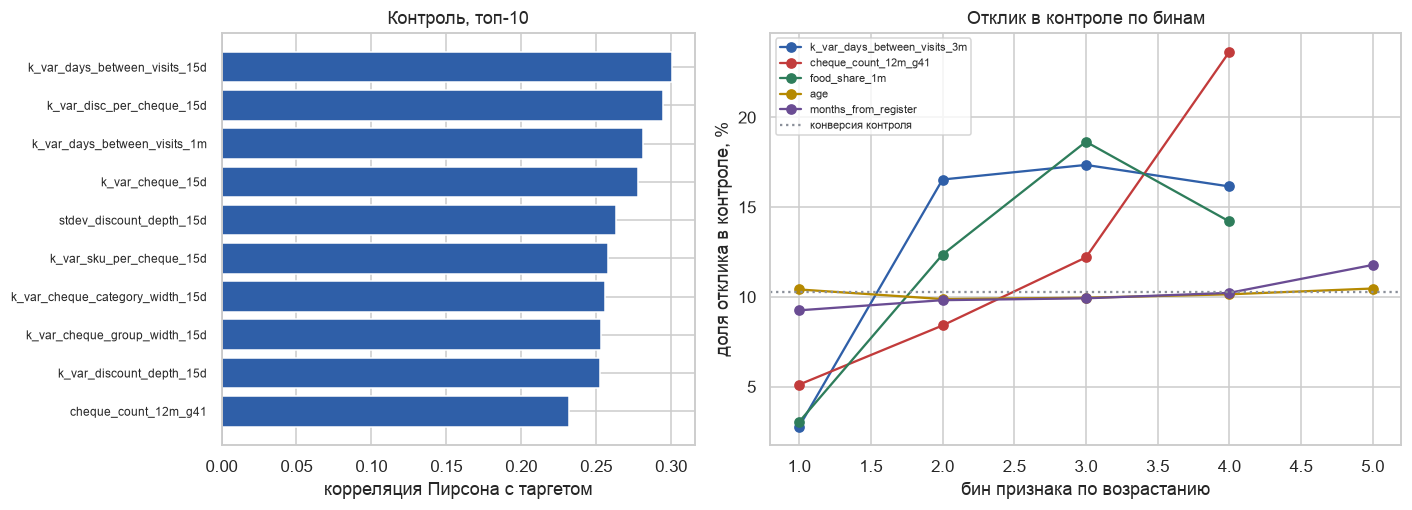

In [12]:
ctrl = ~t
Xc = X.loc[ctrl, num_cols]
yc = y.loc[ctrl].astype(float)
corr_ctrl = Xc.corrwith(yc).rename("corr_y_ctrl")
top_prog = corr_ctrl.abs().sort_values(ascending=False).head(12).index
display(corr_ctrl.loc[top_prog].round(4).to_frame())


def bins_of(s, nb=5):
    """Квантильные бины по наблюдаемым значениям. Пропуск — отдельная категория."""
    s = pd.Series(s).astype("float64")
    if s.notna().sum() == 0:
        return pd.Categorical(["NaN"] * len(s), categories=["NaN"], ordered=True)
    q = np.unique(s.quantile(np.linspace(0, 1, nb + 1)).dropna().to_numpy())
    if q.size < 3:
        vals = np.sort(s.dropna().unique())[:nb]
        lab = s.map(lambda v: "NaN" if pd.isna(v) else f"{v:g}")
        cats = [f"{v:g}" for v in vals] + ["NaN"]
    else:
        cut = pd.cut(s, bins=q, include_lowest=True)
        lab = cut.astype(str).where(s.notna(), "NaN")
        cats = [str(c) for c in cut.cat.categories] + ["NaN"]
    return pd.Categorical(lab, categories=cats, ordered=True)


show = [
    "k_var_days_between_visits_3m",
    "cheque_count_12m_g41",
    "food_share_1m",
    "age",
    "months_from_register",
]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [0.9, 1.2]})

tp = corr_ctrl.loc[top_prog[:10]].iloc[::-1]
axes[0].barh(tp.index.str.slice(0, 36), tp.values, color=BLUE)
axes[0].axvline(0, color=GREY, lw=1)
axes[0].tick_params(axis="y", labelsize=8)
axes[0].set_xlabel("корреляция Пирсона с таргетом")
axes[0].set_title("Контроль, топ-10")

palette = [BLUE, RED, GREEN, "#b58900", "#6a4c93"]
for col, color in zip(show, palette):
    bands = pd.Series(bins_of(Xc[col]), index=Xc.index)
    rr = yc.groupby(bands, observed=True).mean()
    rr = rr[rr.index.astype(str) != "NaN"]
    axes[1].plot(
        np.arange(1, len(rr) + 1),
        rr.to_numpy() * 100,
        marker="o",
        color=color,
        label=col[:32],
    )
axes[1].axhline(cr_control * 100, color=GREY, ls=":", label="конверсия контроля")
axes[1].set_xlabel("бин признака по возрастанию")
axes[1].set_ylabel("доля отклика в контроле, %")
axes[1].set_title("Отклик в контроле по бинам")
axes[1].legend(fontsize=7, loc="best")

fig.tight_layout()
plt.show()


near-constant, доля моды > 99%: 0 → []
слабых по |Gini| < 0.02: 4
Топ-5 по |Gini| на контроле:


,auc_y,gini,mode_share,miss
k_var_disc_per_cheque_15d,0.7448,0.4895,0.5162,0.1988
k_var_cheque_15d,0.7419,0.4839,0.5161,0.1990
k_var_days_between_visits_1m,0.7368,0.4735,0.6123,0.1337
k_var_discount_depth_15d,0.7338,0.4676,0.5424,0.2044
stdev_discount_depth_15d,0.7334,0.4669,0.5424,0.2044


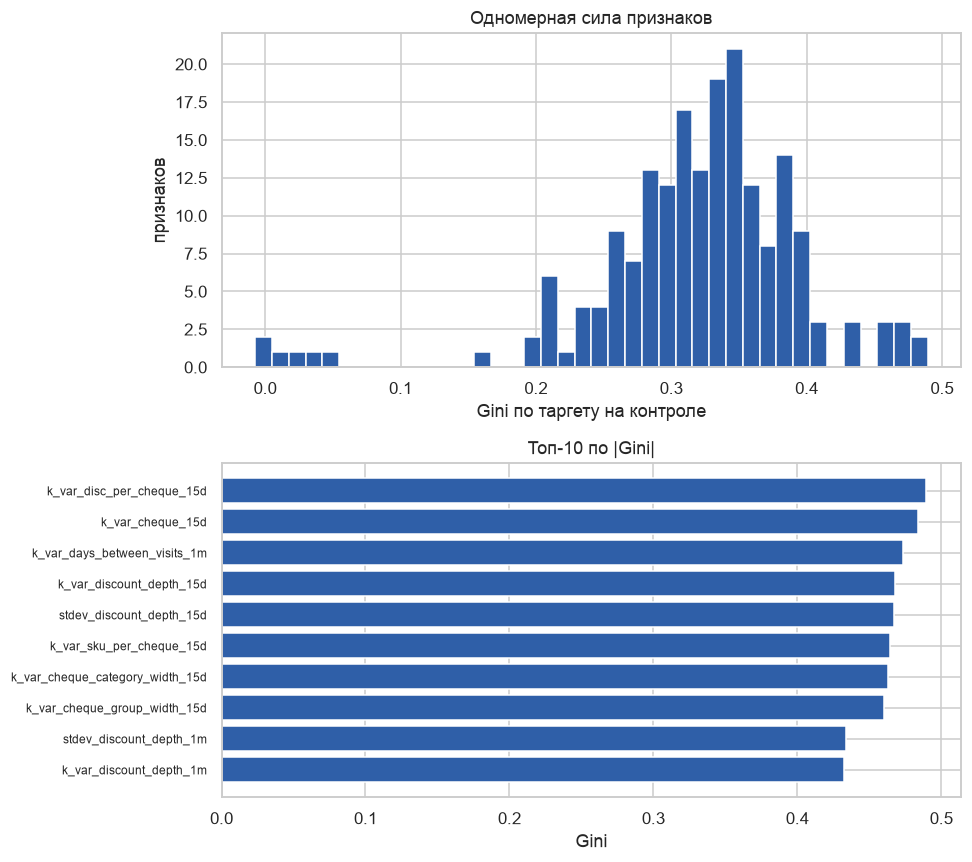

In [13]:
def auc_rank(x, pos):
    """AUC признака как ранжирования бинарной метки. Пропуски исключаются."""
    ok = ~np.isnan(x)
    xx, pp = x[ok], pos[ok]
    n1, n0 = int(pp.sum()), int((~pp).sum())
    if min(n1, n0) < 10 or np.all(xx == xx[0]):
        return np.nan
    ranks = st.rankdata(xx)
    return (ranks[pp].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


A = X[num_cols].to_numpy(np.float32)
Ac = A[~t.to_numpy()]
yc_bool = y.loc[ctrl].to_numpy() > 0
auc_y = pd.Series(
    [auc_rank(Ac[:, j].astype(float), yc_bool) for j in range(len(num_cols))],
    index=num_cols,
    name="auc_y",
)
gini = (2 * auc_y - 1).rename("gini")

d_idx = np.random.default_rng(1).choice(n, size=100_000, replace=False)
mode_share = X[num_cols].iloc[d_idx].apply(
    lambda s: s.value_counts(normalize=True, dropna=False).iloc[0]
)
near_const = mode_share[mode_share > 0.99].index.tolist()
weak = gini[gini.abs() < 0.02].index.tolist()

screen = pd.concat(
    [auc_y, gini, mode_share.rename("mode_share"), miss.rename("miss")],
    axis=1,
)
print(f"near-constant, доля моды > 99%: {len(near_const)} → {near_const}")
print(f"слабых по |Gini| < 0.02: {len(weak)}")
print("Топ-5 по |Gini| на контроле:")
display(screen.reindex(gini.abs().sort_values(ascending=False).index).head(5).round(4))

fig, axes = plt.subplots(2, 1, figsize=(9, 8))
axes[0].hist(gini.dropna(), bins=40, color=BLUE)
axes[0].set_xlabel("Gini по таргету на контроле")
axes[0].set_ylabel("признаков")
axes[0].set_title("Одномерная сила признаков")

top_g = gini.reindex(gini.abs().sort_values(ascending=False).index).head(10).iloc[::-1]
axes[1].barh(top_g.index, top_g.values, color=BLUE)
axes[1].tick_params(axis="y", labelsize=8)
axes[1].set_xlabel("Gini")
axes[1].set_title("Топ-10 по |Gini|")
fig.tight_layout()
plt.show()


Всего пар: 18336
Пар с |ρ| > 0.8: 326
Пар с |ρ| > 0.9: 105
Пар с |ρ| > 0.95: 53
Топ-20 пар:


,,|ρ|
k_var_days_between_visits_15d,stdev_days_between_visits_15d,0.998
cheque_count_3m_g57,sale_count_3m_g57,0.998
k_var_discount_depth_15d,stdev_discount_depth_15d,0.994
cheque_count_6m_g57,sale_count_6m_g57,0.993
cheque_count_12m_g57,sale_count_12m_g57,0.992
mean_discount_depth_15d,promo_share_15d,0.990
sale_count_3m_g33,sale_sum_3m_g33,0.986
sale_count_6m_g33,sale_sum_6m_g33,0.985
crazy_purchases_cheque_count_6m,crazy_purchases_goods_count_6m,0.985
k_var_count_per_cheque_15d_g24,k_var_disc_share_15d_g24,0.982


Признаков с max |ρ| > 0.8: 169
Признаков с max |ρ| > 0.95: 72


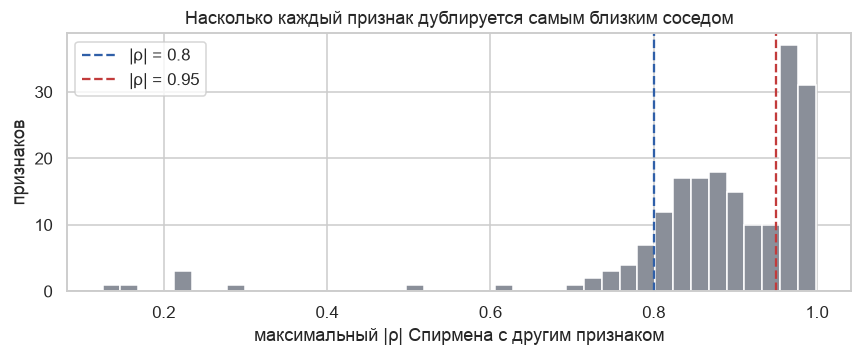

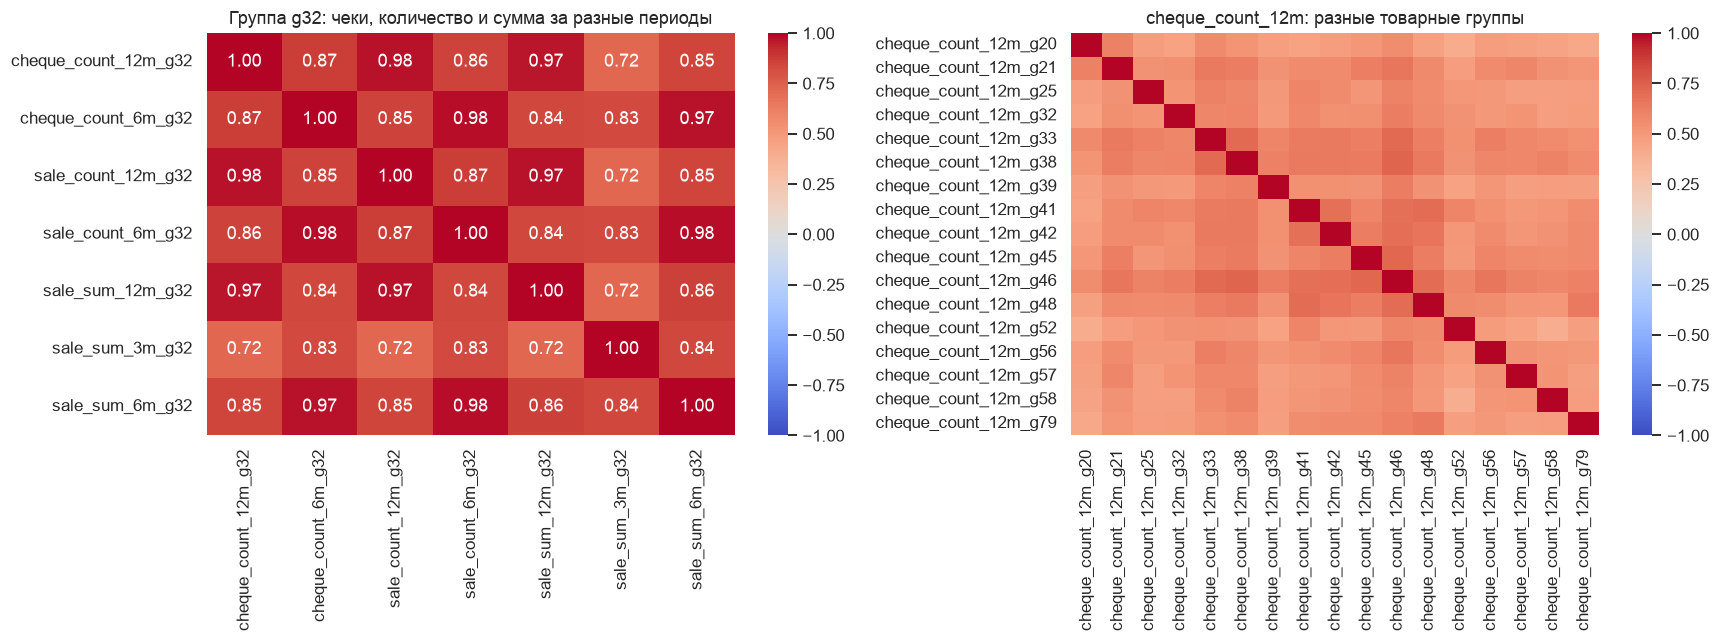

In [14]:
# 100 тыс. строк и random_state=42: на этой подвыборке |ρ| > 0.8 у 326 пар, |ρ| > 0.9 у 105.
corr_sample = X_raw.drop(columns="gender").sample(100_000, random_state=42)
corr = corr_sample.corr(method="spearman")
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()

print(f"Всего пар: {len(upper)}")
print(f"Пар с |ρ| > 0.8: {int((upper.abs() > 0.8).sum())}")
print(f"Пар с |ρ| > 0.9: {int((upper.abs() > 0.9).sum())}")
print(f"Пар с |ρ| > 0.95: {int((upper.abs() > 0.95).sum())}")
print("Топ-20 пар:")
display(upper.abs().sort_values(ascending=False).head(20).to_frame("|ρ|").round(3))

rmax = corr.abs().mask(np.eye(len(corr), dtype=bool)).max(axis=1)
print(f"Признаков с max |ρ| > 0.8: {int((rmax > 0.8).sum())}")
print(f"Признаков с max |ρ| > 0.95: {int((rmax > 0.95).sum())}")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(rmax.dropna(), bins=40, color=GREY)
ax.axvline(0.8, color=BLUE, ls="--", label="|ρ| = 0.8")
ax.axvline(0.95, color=RED, ls="--", label="|ρ| = 0.95")
ax.set_xlabel("максимальный |ρ| Спирмена с другим признаком")
ax.set_ylabel("признаков")
ax.set_title("Насколько каждый признак дублируется самым близким соседом")
ax.legend()
fig.tight_layout()
plt.show()

cols_periods = [
    c
    for c in corr.columns
    if (c.startswith("cheque_count") and c.endswith("_g32"))
    or (c.startswith(("sale_count", "sale_sum")) and c.endswith("_g32"))
]
cols_groups = [c for c in corr.columns if c.startswith("cheque_count_12m")]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(
    corr.loc[cols_periods, cols_periods],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0],
)
axes[0].set_title("Группа g32: чеки, количество и сумма за разные периоды")
sns.heatmap(
    corr.loc[cols_groups, cols_groups],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title("cheque_count_12m: разные товарные группы")
fig.tight_layout()
plt.show()


In [15]:
hi = upper[upper.abs() > 0.95]
adj = {}
for (a, b), _rho in hi.items():
    adj.setdefault(a, set()).add(b)
    adj.setdefault(b, set()).add(a)

# Идём от сильных по |Gini| к слабым: признак остаётся, его соседи с |ρ| > 0.95 уходят.
drop_dup = set()
drop_rows = []
for feature in gini.abs().sort_values(ascending=False).index:
    if feature in drop_dup or feature not in adj:
        continue
    victims = sorted(q for q in adj[feature] if q not in drop_dup)
    for other in victims:
        drop_rows.append(
            {
                "оставить": feature,
                "убрать": other,
                "|ρ|": abs(float(corr.loc[feature, other])),
                "|Gini| оставленного": abs(float(gini.get(feature, np.nan))),
                "|Gini| убранного": abs(float(gini.get(other, np.nan))),
            }
        )
    drop_dup |= set(victims)

print(f"Пар с |ρ| > 0.95: {len(hi)}")
print(f"Признаков к исключению как почти дубликатов: {len(drop_dup)}")
display(pd.DataFrame(drop_rows).round(3))


Пар с |ρ| > 0.95: 53
Признаков к исключению как почти дубликатов: 40


,оставить,убрать,|ρ|,|Gini| оставленного,|Gini| убранного
0,k_var_disc_per_cheque_15d,k_var_cheque_15d,0.980,0.490,0.484
1,k_var_disc_per_cheque_15d,k_var_sku_per_cheque_15d,0.952,0.490,0.465
2,k_var_discount_depth_15d,stdev_discount_depth_15d,0.994,0.468,0.467
3,k_var_cheque_category_width_15d,k_var_cheque_group_width_15d,0.976,0.463,0.460
4,stdev_discount_depth_1m,k_var_discount_depth_1m,0.976,0.434,0.433
...,...,...,...,...,...
35,k_var_disc_share_1m_g54,k_var_sku_price_1m_g54,0.961,0.269,0.266
36,k_var_disc_share_1m_g40,k_var_sku_price_1m_g40,0.962,0.263,0.262
37,cheque_count_3m_g57,sale_count_3m_g57,0.998,0.239,0.236
38,k_var_disc_share_15d_g24,k_var_count_per_cheque_15d_g24,0.982,0.216,0.214


**Вывод.** Сильнее всего с визитом в контроле связаны частота и разнообразие покупок на коротком окне, в первую очередь около 15 дней. Univariate AUC у лидеров доходит примерно до 0.745, Gini около 0.49. У остальных полей связь умеренная или слабая. Признаков с модой выше 99% нет.

На 18 336 парах Спирмена |ρ| > 0.8 у 326 пар и |ρ| > 0.9 у 105. Внутри одной товарной группы разные горизонты `cheque_count` связаны сильно: у g32 |ρ| выше 0.8. Между товарными группами на одном горизонте связь умеренная, около 0.5, то есть группы несут разную информацию. Почти повторяют друг друга семейства `cheque_count` / `sale_count` / `sale_sum`, `crazy_purchases_cheque_count` / `crazy_purchases_goods_count`, `mean_discount_depth_15d` / `promo_share_15d` и пары `stdev_*` / `k_var_*`.

Почти дубликаты с |ρ| > 0.95 убираем по списку выше, в кластере остаётся признак с большим |Gini| на контроле.


## 5. Гетерогенность эффекта

Для каждого числового признака, включая `response_sms` и `response_viber`, строим квантильные бины и отдельный бин пропуска. В бине uplift — доля визитов в test минус доля в control. Сегмент остаётся в сравнении, если и в test, и в control не меньше 300 клиентов.

Однородность uplift между бинами проверяет Q-тест Кохрана. Считается взвешенное среднее uplift с весами 1/SE², затем сумма взвешенных квадратов отклонений бинов от этого среднего. Статистика сравнивается с хи-квадрат. Поправку на число признаков даёт процедура Бенджамини–Хохберга.

Отдельно смотрим четыре понятных разреза: пол, число пропусков в профиле, возраст и срок с регистрации.


In [16]:
def segment_uplift(labels, treat_mask, outcome, min_n=300):
    cat = pd.Categorical(labels)
    codes = cat.codes.astype(np.int64)
    k = len(cat.categories)
    ok = codes >= 0
    t_ok = np.asarray(treat_mask)[ok].astype(np.int64)
    y_ok = (np.asarray(outcome)[ok] > 0).astype(np.int64)
    idx = codes[ok] * 4 + t_ok * 2 + y_ok
    cnt = np.bincount(idx, minlength=k * 4).reshape(k, 2, 2)
    n_c = cnt[:, 0].sum(1)
    n_t = cnt[:, 1].sum(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        rr_c = cnt[:, 0, 1] / n_c
        rr_t = cnt[:, 1, 1] / n_t
        se = np.sqrt(rr_t * (1 - rr_t) / n_t + rr_c * (1 - rr_c) / n_c)
    out = pd.DataFrame(
        {
            "seg": [str(c) for c in cat.categories],
            "n": n_c + n_t,
            "n_t": n_t,
            "n_c": n_c,
            "rr_t": rr_t,
            "rr_c": rr_c,
            "uplift": rr_t - rr_c,
            "se": se,
        }
    )
    return out[(out.n_t >= min_n) & (out.n_c >= min_n)].reset_index(drop=True)


def cochran_q(seg):
    u = seg.uplift.to_numpy()
    w = 1.0 / seg.se.to_numpy() ** 2
    Q = float((w * (u - (u * w).sum() / w.sum()) ** 2).sum())
    df = len(seg) - 1
    return Q, df, float(st.chi2.sf(Q, df))


def bh_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    m = len(p_values)
    ranked = p_values[order] * m / np.arange(1, m + 1)
    adj = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(m, dtype=float)
    out[order] = np.clip(adj, 0, 1)
    return out


rows, segs_cache = [], {}
treat_np = t.to_numpy()
outcome_np = y.to_numpy(dtype=float)
for col in num_cols:
    seg = segment_uplift(bins_of(X[col]), treat_np, outcome_np)
    if len(seg) < 2:
        continue
    Q, dfree, p = cochran_q(seg)
    segs_cache[col] = seg
    rows.append(
        {
            "feature": col,
            "bins": len(seg),
            "Q": Q,
            "df": dfree,
            "p": p,
            "u_min": seg.uplift.min(),
            "u_max": seg.uplift.max(),
        }
    )

H = pd.DataFrame(rows).sort_values("Q", ascending=False)
H["p_bh"] = bh_adjust(H["p"].to_numpy())

print(
    f"Проверено признаков: {len(H)}; "
    f"значимо неоднородны при BH q < 0.05: {int((H['p_bh'] < 0.05).sum())}"
)
view = H.head(8).assign(u_min=lambda d: d.u_min * 100, u_max=lambda d: d.u_max * 100)
display(view.round({"Q": 1, "p": 4, "p_bh": 3, "u_min": 2, "u_max": 2}).set_index("feature"))

spread = H.assign(width=H["u_max"] - H["u_min"]).sort_values("width", ascending=False)
print("Самый большой разброс uplift. Крупный размах при большом p_bh — шум мелких бинов:")
display(
    spread.head(3)
    .assign(u_min=lambda d: d.u_min * 100, u_max=lambda d: d.u_max * 100)
    .round({"Q": 1, "p_bh": 2, "u_min": 2, "u_max": 2, "width": 3})
    .set_index("feature")[["bins", "Q", "p_bh", "u_min", "u_max"]]
)


/var/folders/c5/dwqcr0qd20l4qb3yl0dkxh180000gn/T/ipykernel_7237/3635360495.py:23: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  return pd.Categorical(lab, categories=cats, ordered=True)
/var/folders/c5/dwqcr0qd20l4qb3yl0dkxh180000gn/T/ipykernel_7237/3635360495.py:23: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  return pd.Categorical(lab, categories=cats, ordered=True)
/var/folders/c5/dwqcr0qd20l4qb3yl0dkxh180000gn/T/ipykernel_7237/3635360495.py:23: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  return pd.Categorical(lab, categories=cats, ordered=True)
/var/folders/c5/dwqcr0qd20l4qb3yl0dkxh180000gn

Проверено признаков: 191; значимо неоднородны при BH q < 0.05: 17


,bins,Q,df,p,u_min,u_max,p_bh
feature,,,,,,,
k_var_days_between_visits_3m,5,22.1,4,0.0002,0.09,1.23,0.019
k_var_disc_share_6m_g27,5,21.2,4,0.0003,0.33,1.50,0.019
response_sms,4,19.1,3,0.0003,-0.08,0.86,0.019
k_var_count_per_cheque_6m_g27,5,18.6,4,0.0009,0.31,1.12,0.040
k_var_sku_price_6m_g27,5,18.4,4,0.0010,0.37,1.22,0.040
k_var_sku_price_6m_g48,5,15.5,4,0.0037,0.33,1.29,0.048
food_share_1m,4,15.5,3,0.0015,0.29,1.07,0.046
sale_count_3m_g24,5,15.3,4,0.0040,0.30,1.13,0.048


Самый большой разброс uplift. Крупный размах при большом p_bh — шум мелких бинов:


,bins,Q,p_bh,u_min,u_max
feature,,,,,
crazy_purchases_cheque_count_1m,5,2.5,0.77,0.03,2.11
cheque_count_6m_g41,5,15.2,0.05,-0.78,1.25
cheque_count_6m_g48,5,13.1,0.09,-0.78,1.25


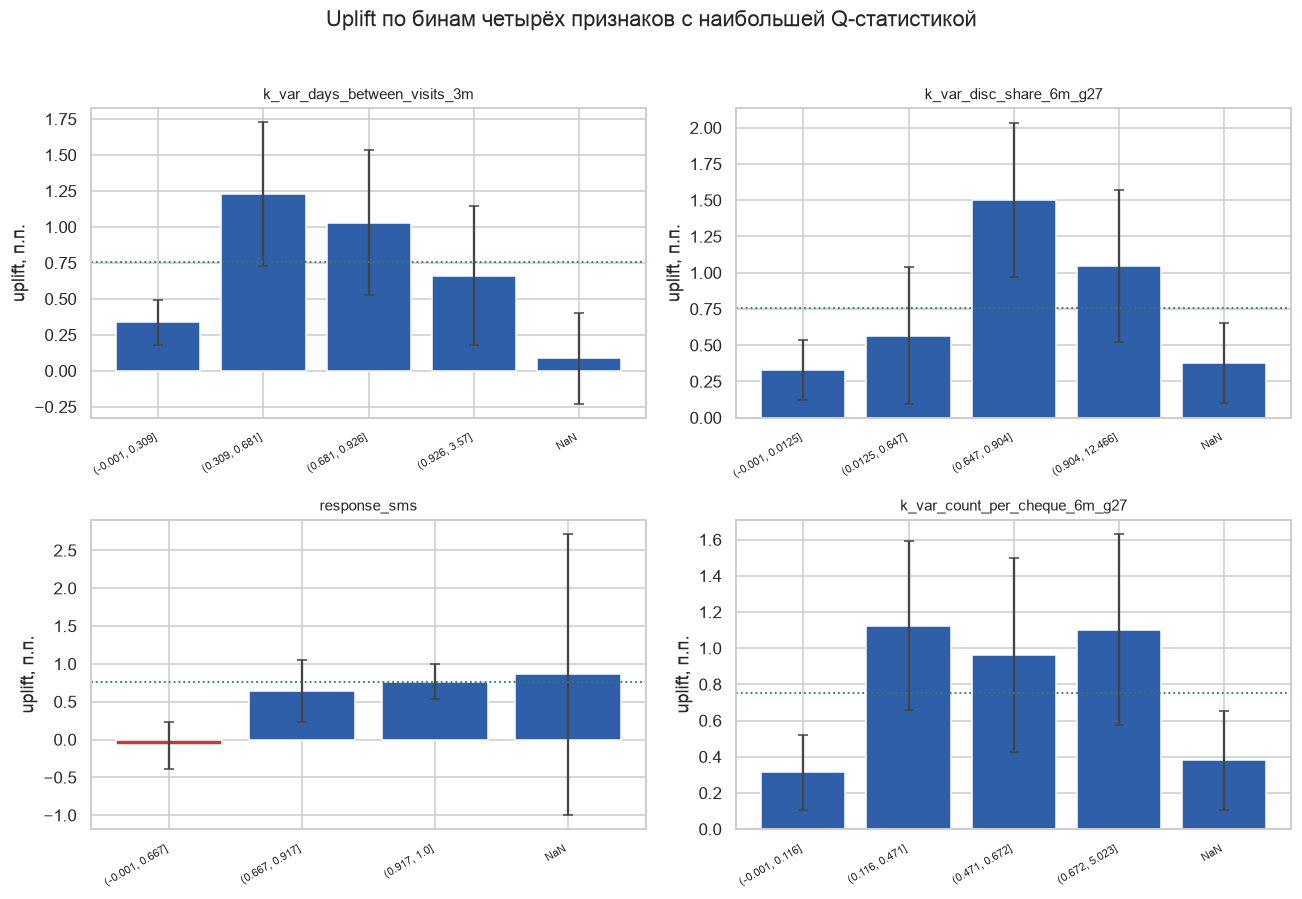

In [17]:
def plot_uplift_bars(ax, seg, title):
    colors = [RED if u < 0 else BLUE for u in seg.uplift]
    xpos = np.arange(len(seg))
    ax.bar(
        xpos,
        seg.uplift * 100,
        color=colors,
        yerr=1.96 * seg.se * 100,
        capsize=3,
        ecolor="#444",
    )
    ax.axhline(ate * 100, color=GREEN, ls=":", lw=1.2)
    ax.set_xticks(xpos)
    ax.set_xticklabels(seg.seg, rotation=30, ha="right", fontsize=7)
    ax.set_ylabel("uplift, п.п.")
    ax.set_title(title, fontsize=10)


names = H.feature.head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, name in zip(axes.ravel(), names):
    plot_uplift_bars(ax, segs_cache[name], name[:42])
fig.suptitle("Uplift по бинам четырёх признаков с наибольшей Q-статистикой", y=1.02)
fig.tight_layout()
plt.show()


Пол: Q = 0.2 (df 1), p = 0.6727; uplift от +0.74 до +0.81 п.п.
Пропусков в профиле: Q = 12.1 (df 3), p = 0.0071; uplift от +0.36 до +0.91 п.п.
Возраст: Q = 5.3 (df 5), p = 0.3829; uplift от +0.41 до +0.98 п.п.
Месяцев с регистрации: Q = 4.8 (df 5), p = 0.4386; uplift от +0.51 до +1.11 п.п.


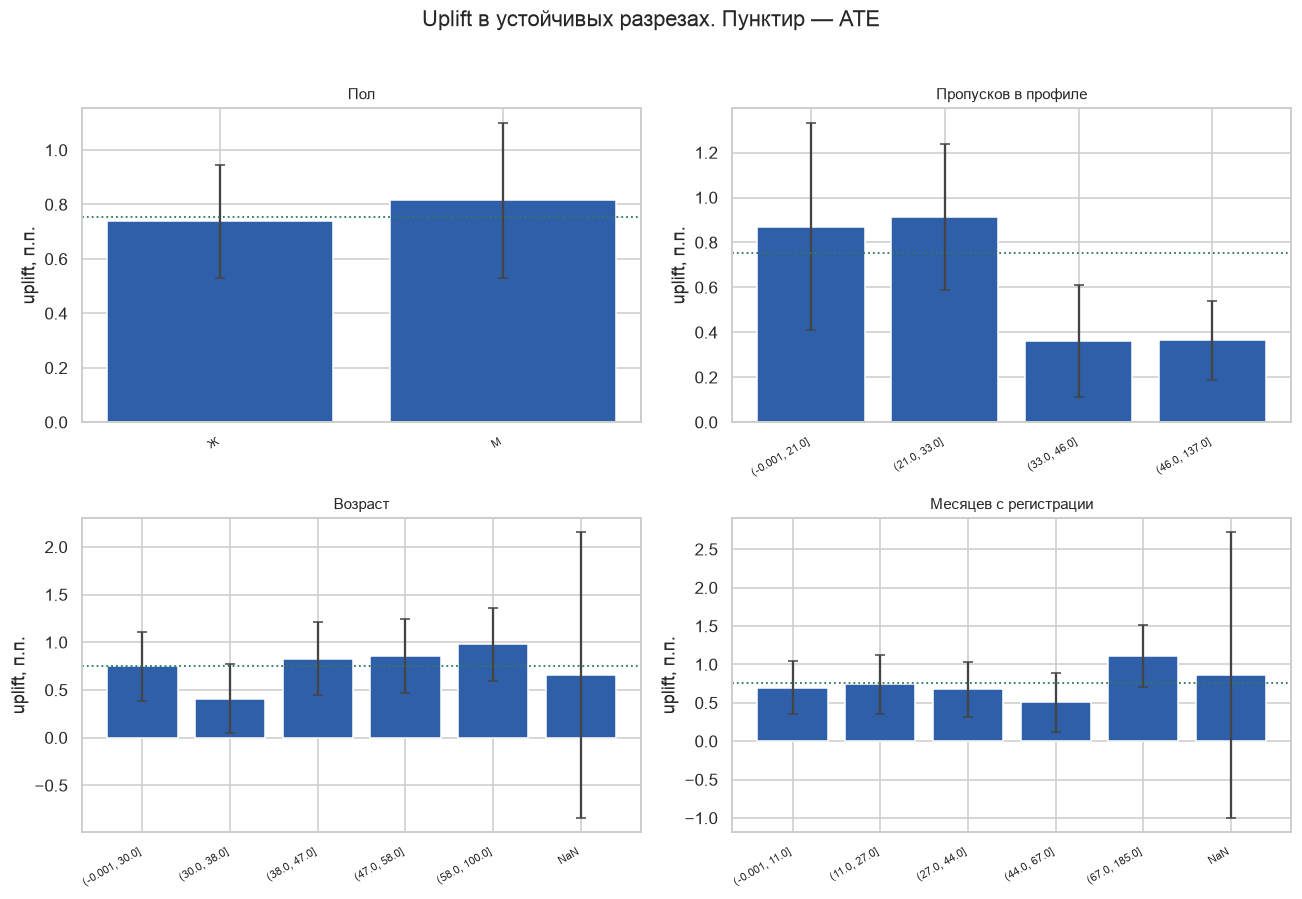

In [18]:
cuts = {
    "Пол": X["gender"].astype(str),
    "Пропусков в профиле": bins_of(nan_per_row.astype(float), nb=4),
    "Возраст": bins_of(X["age"]),
    "Месяцев с регистрации": bins_of(X["months_from_register"]),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (title, labels) in zip(axes.ravel(), cuts.items()):
    seg = segment_uplift(labels, treat_np, outcome_np)
    Q, dfree, p = cochran_q(seg)
    print(
        f"{title}: Q = {Q:.1f} (df {dfree}), p = {p:.4f}; "
        f"uplift от {seg.uplift.min() * 100:+.2f} до {seg.uplift.max() * 100:+.2f} п.п."
    )
    plot_uplift_bars(ax, seg, title)

fig.suptitle("Uplift в устойчивых разрезах. Пунктир — ATE", y=1.02)
fig.tight_layout()
plt.show()


**Вывод.** Неоднородность есть и после поправки Бенджамини–Хохберга остаётся примерно у 17 признаков. Она собрана в признаках активности. По сегментам uplift лежит примерно в коридоре 0.4–0.9 п.п. вокруг ATE.

Самый понятный разрез — полнота профиля. У клиентов с малым числом пропусков uplift около 0.9 п.п., у разреженных профилей около 0.4 п.п., p этого разреза около 0.007. Пол, возраст и срок с регистрации эффект не меняют. Здесь число пропусков говорит о силе эффекта у клиента.

## 6. Выводы для моделирования

Данные для uplift годятся. По признакам до кампании test и control сопоставимы, средний эффект положительный и значимый: конверсия 10.26% в control и 11.01% в test, ATE +0.75 п.п., 95% интервал около +0.59…+0.92 п.п., относительный прирост около 7.4%. Гетерогенность узкая, при этом она не пустая: около 17 признаков и полнота профиля.

**Признаки**

- `response_sms` и `response_viber` в модель не входят: это альтернативные отклики. У `response_sms` ещё и |SMD| ≈ 0.20.
- Пропуски оставляем как есть. Они в основном означают отсутствие покупок, между группами сбалансированы (максимальная разница доли NaN около 0.7 п.п.), а число пропусков в строке само делит uplift, около 0.9 против 0.4 п.п. В матрицу стоит добавить признак «число NaN в строке».
- Почти константных признаков нет.
- Из кластера Спирмена с |ρ| > 0.95 оставляем один признак, с большим |Gini| на контроле. Кого убрать, печатает раздел 4 и ячейка ниже.
- Скос счётных и денежных признаков для деревьев оставляем. Для линейной модели берём логарифм.

In [19]:
print("Исключить как утечки:", LEAK)
print(f"Исключить как почти дубликаты (|ρ| > 0.95), {len(drop_dup)} шт.:")
print(sorted(drop_dup))
print("Добавить признак: число NaN в строке")
print("Сплит: 80/20, стратификация по (group, response_att)")
print("Метрики: qini_auc_score, uplift_at_k на 30%")


Исключить как утечки: ['response_sms', 'response_viber']
Исключить как почти дубликаты (|ρ| > 0.95), 40 шт.:
['crazy_purchases_goods_count_12m', 'crazy_purchases_goods_count_6m', 'k_var_cheque_15d', 'k_var_cheque_group_width_15d', 'k_var_count_per_cheque_15d_g24', 'k_var_count_per_cheque_1m_g24', 'k_var_count_per_cheque_1m_g27', 'k_var_disc_share_15d_g49', 'k_var_disc_share_1m_g27', 'k_var_disc_share_3m_g32', 'k_var_disc_share_6m_g32', 'k_var_discount_depth_1m', 'k_var_sku_per_cheque_15d', 'k_var_sku_price_15d_g34', 'k_var_sku_price_1m_g24', 'k_var_sku_price_1m_g40', 'k_var_sku_price_1m_g44', 'k_var_sku_price_1m_g54', 'k_var_sku_price_6m_g32', 'promo_share_15d', 'sale_count_12m_g32', 'sale_count_12m_g33', 'sale_count_12m_g57', 'sale_count_3m_g57', 'sale_count_6m_g25', 'sale_count_6m_g32', 'sale_count_6m_g33', 'sale_count_6m_g57', 'sale_sum_12m_g32', 'sale_sum_12m_g54', 'sale_sum_3m_g24', 'sale_sum_3m_g32', 'sale_sum_3m_g33', 'sale_sum_6m_g24', 'sale_sum_6m_g32', 'sale_sum_6m_g33', 'sal